# Comparative Analysis of Classification Algorithms

**Student Name:** Parth Nandkishor Shingane  
**PRN:** 202401040210  
**Roll No.:** 51  
**Division:** A-A2  
**Github:**


## **Aim**
Develop and compare four classification algorithms—Support Vector Machine (SVM), Decision Tree, K-Nearest Neighbors (KNN), and Naïve Bayes—using accuracy, precision, recall, F1-score, and loss. Discuss the suitability of each algorithm for different classification tasks.

## **Dataset**
This notebook uses the provided `sdg3_health_engineered.csv` dataset containing country-year health and socioeconomic indicators. The target variable is `infant_mort_risk`, with four categories: low, moderate, high, and very high.

The direct infant mortality measure and its direct derivative are excluded from the input features to reduce target leakage. Data is split by country, so the same country does not appear in both training and test sets. The results are for educational analysis, not clinical decision-making.

## 1. Import libraries and load dataset

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "sdg3_health_engineered.csv"  # Keep the CSV beside this notebook

sns.set_theme(style="whitegrid")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Target distribution:")
display(df["infant_mort_risk"].value_counts().to_frame("Records"))
display(df.head())

Dataset shape: (1962, 64)
Target distribution:


,Records
infant_mort_risk,
moderate (10-30),687
very high (>60),500
low (<10),465
high (30-60),309


,iso3,country,region,income_group,year,life_expectancy,infant_mortality_per_1000,birth_rate_per_1000,death_rate_per_1000,health_expenditure_pct_gdp,...,era_code,gdp_quantile_bin_code,life_exp_equal_width_code,region_East Asia & Pacific,region_Europe & Central Asia,region_Latin America & Caribbean,"region_Middle East, North Africa, Afghanistan & Pakistan",region_North America,region_South Asia,region_Sub-Saharan Africa
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1970,38.9531,166.558,51.207,25.38104,5.766701,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1971,38.9531,166.558,51.303,25.38104,5.766701,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1972,38.9531,166.558,51.244,25.38104,5.766701,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1973,38.9531,166.558,51.278,25.36400,5.766701,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1974,39.4690,166.558,51.373,24.88900,5.766701,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## 2. Prepare the data

In [ ]:
TARGET = "infant_mort_risk"

# Remove direct target leakage and identifiers/target-encoding helpers.
drop_columns = [
    TARGET, "infant_mortality_per_1000", "infant_mort_yoy_change",
    "infant_mort_risk_code", "country", "iso3", "country_target_enc",
    "country_freq", "region_label"
]
drop_columns += [c for c in df.columns if c.startswith("region_") or c.endswith("_code")]

X = df.drop(columns=[c for c in set(drop_columns) if c in df.columns], errors="ignore")
y = df[TARGET].astype(str)
groups = df["iso3"]
X = X.dropna(axis=1, how="all")

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
class_names = sorted(y.unique())

# Grouped split: countries in the test set are not present in training.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

Training rows: 1540
Test rows: 422
Numeric features: 40
Categorical features: 5


## 3. Visualize the target distribution

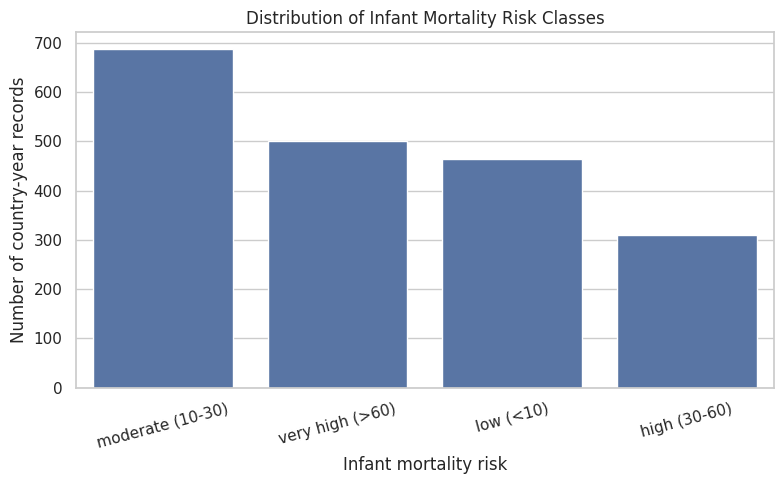

In [ ]:
# Graph 1: distribution of classification target
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Distribution of Infant Mortality Risk Classes")
plt.xlabel("Infant mortality risk")
plt.ylabel("Number of country-year records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Preprocessing and define models

In [ ]:
numeric_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocess, numeric_features),
    ("categorical", categorical_preprocess, categorical_features)
], remainder="drop")

model_specs = {
    "SVM": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced", min_samples_leaf=5),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naïve Bayes": GaussianNB()
}

models = {
    name: Pipeline([("preprocess", preprocessor), ("classifier", estimator)])
    for name, estimator in model_specs.items()
}
print("Models defined:", ", ".join(models.keys()))

Models defined: SVM, Decision Tree, KNN, Naïve Bayes


## 5. Train and evaluate the models

In [ ]:
results = []
predictions = {}
probabilities = {}

# Filter out 'nan' from class names to prevent alignment errors with missing target values
clean_class_names = [c for c in class_names if c != 'nan']

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)

    model_classes = list(model.named_steps["classifier"].classes_)
    # Align only valid classes present in both the model classes and the cleaned class names
    proba_aligned = proba[:, [model_classes.index(c) for c in clean_class_names if c in model_classes]]

    predictions[name] = pred
    probabilities[name] = proba_aligned
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Log loss": log_loss(y_test, proba_aligned, labels=clean_class_names)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

Training: SVM
Training: Decision Tree
Training: KNN
Training: Naïve Bayes


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Log loss
Model,,,,,
SVM,0.7180,0.5624,0.5997,0.5708,0.9971
Decision Tree,0.7370,0.5722,0.5909,0.5740,7.2337
KNN,0.7701,0.6407,0.6172,0.6128,6.2710
Naïve Bayes,0.7014,0.5879,0.6020,0.5698,8.5299


## 6. Compare model performance

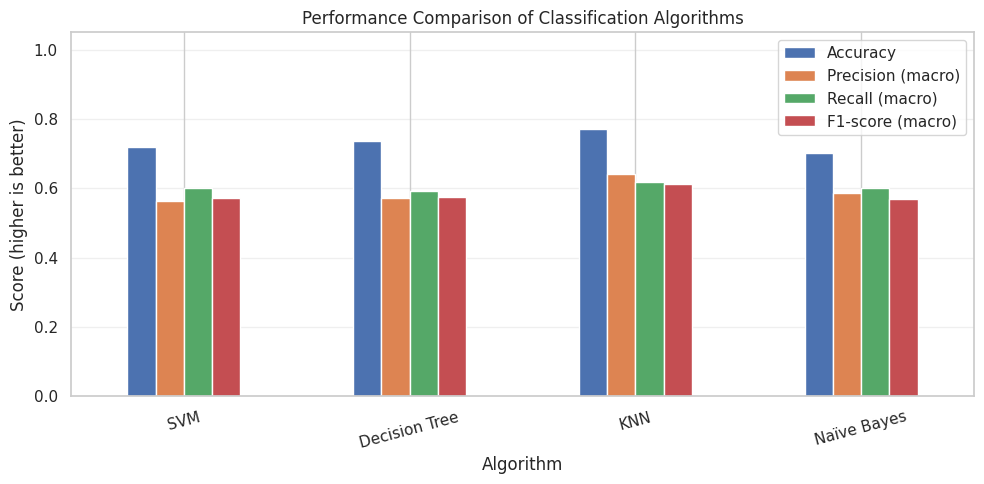

Log loss is included in the results table; lower values indicate better probability predictions.


In [ ]:
# Graph 2: compare all four classification metrics in one figure.
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
ax = results_df[metric_cols].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
ax.set_title("Performance Comparison of Classification Algorithms")
ax.set_ylabel("Score (higher is better)")
ax.set_xlabel("Algorithm")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Log loss is included in the results table; lower values indicate better probability predictions.")

## 7. Classification reports and automatic findings

In [ ]:
for name, pred in predictions.items():
    print("\n" + "=" * 65)
    print(name)
    print(classification_report(
        y_test, pred, labels=class_names, target_names=class_names, zero_division=0
    ))

best_accuracy = results_df["Accuracy"].idxmax()
best_precision = results_df["Precision (macro)"].idxmax()
best_recall = results_df["Recall (macro)"].idxmax()
best_f1 = results_df["F1-score (macro)"].idxmax()
lowest_loss = results_df["Log loss"].idxmin()

print("\nCOMPARATIVE FINDINGS")
print(f"Highest accuracy: {best_accuracy} ({results_df.loc[best_accuracy, 'Accuracy']:.4f})")
print(f"Highest macro precision: {best_precision} ({results_df.loc[best_precision, 'Precision (macro)']:.4f})")
print(f"Highest macro recall: {best_recall} ({results_df.loc[best_recall, 'Recall (macro)']:.4f})")
print(f"Highest macro F1-score: {best_f1} ({results_df.loc[best_f1, 'F1-score (macro)']:.4f})")
print(f"Lowest log loss: {lowest_loss} ({results_df.loc[lowest_loss, 'Log loss']:.4f})")


SVM
                  precision    recall  f1-score   support

    high (30-60)       0.56      0.72      0.63        57
       low (<10)       0.63      0.82      0.71        94
moderate (10-30)       0.73      0.48      0.58       159
             nan       0.00      0.00      0.00         1
 very high (>60)       0.89      0.98      0.94       111

        accuracy                           0.72       422
       macro avg       0.56      0.60      0.57       422
    weighted avg       0.73      0.72      0.71       422


Decision Tree
                  precision    recall  f1-score   support

    high (30-60)       0.55      0.56      0.56        57
       low (<10)       0.61      0.83      0.70        94
moderate (10-30)       0.80      0.57      0.67       159
             nan       0.00      0.00      0.00         1
 very high (>60)       0.90      0.99      0.94       111

        accuracy                           0.74       422
       macro avg       0.57      0.59      0.57

## 8. Suitability of each algorithm

| Algorithm | Advantages | Limitations | Suitable tasks |
|---|---|---|---|
| **SVM** | Handles complex decision boundaries and high-dimensional features | Needs feature scaling and parameter tuning; can be slower on large datasets | Medium-sized datasets with complex class boundaries |
| **Decision Tree** | Easy to interpret; models nonlinear relationships and feature interactions | Can overfit and may be unstable | Tasks requiring understandable decision rules |
| **KNN** | Simple, non-parametric, captures local patterns | Sensitive to scaling and irrelevant features; prediction may be slow | Smaller datasets where nearby examples are similar |
| **Naïve Bayes** | Fast training and prediction; produces class probabilities | Assumes conditional independence; Gaussian variant assumes Gaussian numeric features | Fast baselines and problems with approximately independent features |

## 9. Metric interpretation

- **Accuracy:** proportion of all test records classified correctly.
- **Precision (macro):** average precision across all classes, treating each class equally.
- **Recall (macro):** average recall across all classes, treating each class equally.
- **F1-score (macro):** balances precision and recall across the four classes.
- **Log loss:** evaluates the quality of predicted probabilities; lower is better.

## 10. Conclusion

The results table and second graph compare the four algorithms on the same held-out test set. The automatic findings identify the best model for accuracy, precision, recall, F1-score, and log loss. A suitable classifier should be selected according to the task: use macro recall when missing a risk category is a concern, macro F1 when balancing precision and recall is important, and log loss when probability estimates matter. Accuracy should not be considered alone.

The target is derived from infant mortality, so the original mortality rate and its direct change are excluded from input features to reduce target leakage. The results are educational and describe associations in country-year data, not clinical diagnoses.

### How to run
Keep `sdg3_health_engineered.csv` in the same folder as this notebook. Install `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn` if needed, then run all cells in order.